### Sales Growth Drivers, category level: 2024 vs. 2025

The same analysis performed [for subcategories](https://github.com/TAbramovskaya/dear-neighbour/blob/main/python/sales_drivers.ipynb) can also be applied to categories.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

In [2]:
input_file = "../data/dear_neighbour.xlsx"

sheets = pd.read_excel(input_file, sheet_name=None)
sheet_names = sheets.keys()

sheet_names

dict_keys(['fact_sales', 'dim_products', 'dim_stores', 'dim_customers', 'dim_suppliers'])

In [3]:
sales = sheets['fact_sales']
products = sheets['dim_products']

[As we saw](https://github.com/TAbramovskaya/dear-neighbour/blob/main/python/data_overview.ipynb), selling prices remained relatively stable over the two-year period.

Therefore, we will overlook the fact that we have a single purchase price for each product across both years.

In [4]:
sales['year'] = sales['datetime'].dt.year

sales = (
    sales.merge(
        products[['product_id', 'category', 'subcategory', 'purchase_price_rub']],
        on='product_id',
        how='left'
    )
)

sales['unit_revenue'] = sales['line_total'] / sales['quantity']

sales['cost'] = sales['purchase_price_rub'] * sales['quantity']

sales['gross_profit'] = sales['line_total'] - sales['cost']

sales['gross_before_discount'] = sales['quantity'] * sales['unit_price']

sales['discount_amount'] = sales['gross_before_discount'] - sales['line_total']

sales['loyalty_receipts'] = sales.loc[sales['customer_id'].notna(), 'receipt_id']

In [5]:
summary_by_category = (
    sales
    .groupby(['year', 'category'])
    .agg(
        revenue=('line_total', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        costs=('cost', 'sum'),
        avg_category_receipt_value=('line_total', 'mean'),
        units_sold=('quantity', 'sum'),
        receipts=('receipt_id', 'nunique'),
        loyalty_receipts=('loyalty_receipts', 'nunique'),
        gross_before_discount=('gross_before_discount', 'sum'),
        discount_amount=('discount_amount', 'sum'),
        avg_discount_percent=('discount_percent', 'mean'),
    )
)

In [6]:
summary_by_category['gross_margin'] = summary_by_category['gross_profit'] / summary_by_category['revenue']

summary_by_category['revenue_share'] = (
        summary_by_category['revenue']
        / summary_by_category.groupby(level=['year'])['revenue'].transform('sum')
)

summary_by_category['discount_share'] = (
        summary_by_category['discount_amount']
        / summary_by_category.groupby(level=['year'])['discount_amount'].transform('sum')
)

summary_by_category['discount_share_of_profit'] = (
        summary_by_category['discount_amount']
        / summary_by_category['gross_profit'].replace(0, np.nan)
)

summary_by_category['loyalty_receipts_share'] = (
        summary_by_category['loyalty_receipts']
        / summary_by_category.groupby(level=['year'])['loyalty_receipts'].transform('sum')
)

summary_by_category['avg_unit_price'] = (
        summary_by_category['revenue']
        / summary_by_category['units_sold'].replace(0, np.nan)
)

summary_by_category['avg_category_units_per_receipt'] = (
        summary_by_category['units_sold']
        / summary_by_category['receipts'].replace(0, np.nan)
)

In [7]:
wide = summary_by_category.unstack('year')

metrics = {
    'gross_profit_change': ('gross_profit', 'pct'),
    'units_sold_change': ('units_sold', 'pct'),
    'revenue_share_change': ('revenue_share', 'pp'),
    'discount_share_change': ('discount_share', 'pp'),
    'discount_percent_of_profit_change': ('discount_share_of_profit', 'pp'),
    'loyalty_receipts_share_change': ('loyalty_receipts_share', 'pp'),
    'avg_unit_price_change': ('avg_unit_price', 'pct'),
    'avg_category_receipt_value_change': ('avg_category_receipt_value', 'pct'),
    'avg_category_units_per_receipt_change': ('avg_category_units_per_receipt', 'pct'),
    'receipts_change': ('receipts', 'pct'),
}

categories_yoy = pd.DataFrame(index=wide.index)

for column, (metric, change_type) in metrics.items():
    old = wide[metric][2024]
    new = wide[metric][2025]

    if change_type == 'pct':
        change = 100 * (new - old) / old.replace(0, np.nan)
    elif change_type == 'pp':
        change = 100 * (new - old)
    else:
        change = new - old

    categories_yoy[column] = change

In [8]:
categories_yoy = categories_yoy.sort_values('gross_profit_change', ascending=False)

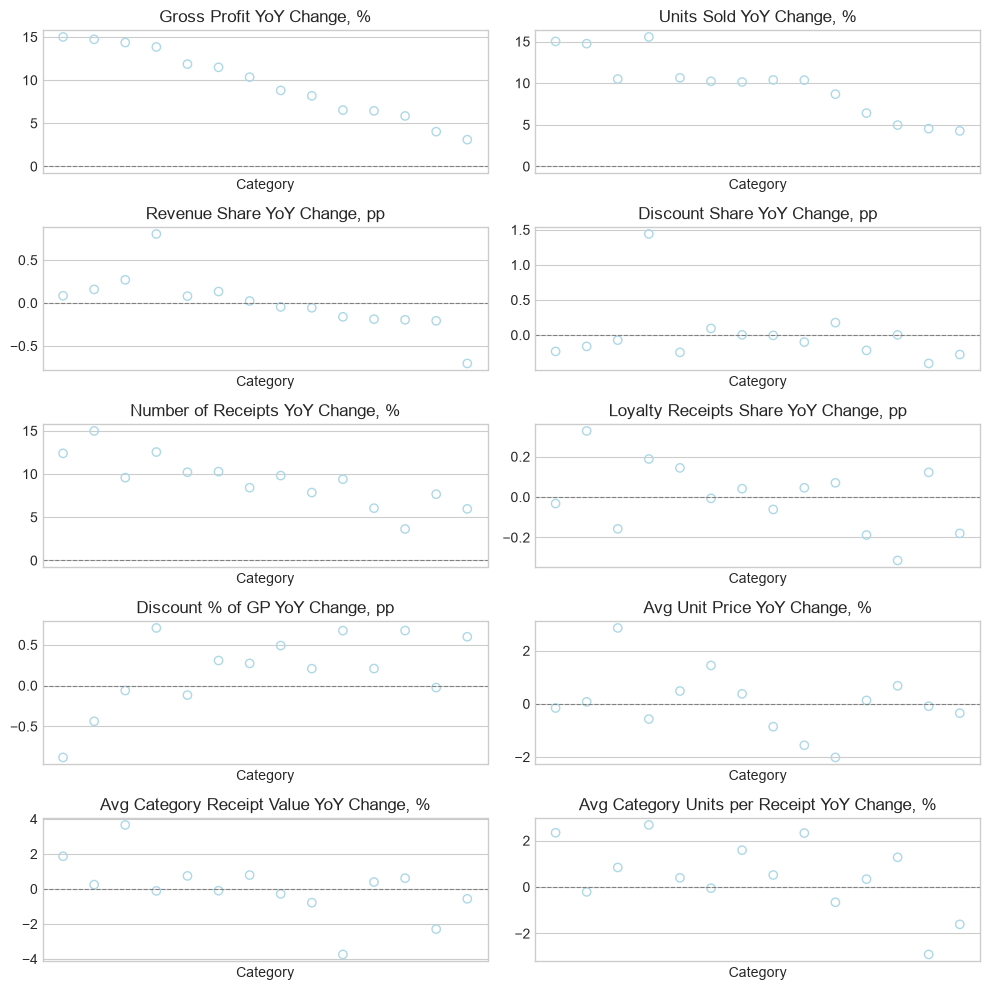

In [9]:
fig, axes = plt.subplots(5, 2, figsize=(10, 10))

metrics = [
    ('gross_profit_change', 'Gross Profit YoY Change, %', 'Change, %'),
    ('units_sold_change', 'Units Sold YoY Change, %', 'Change, %'),
    ('revenue_share_change', 'Revenue Share YoY Change, pp', 'Change, pp'),
    ('discount_share_change', 'Discount Share YoY Change, pp', 'Change, pp'),
    ('receipts_change', 'Number of Receipts YoY Change, %', 'Change, %'),
    ('loyalty_receipts_share_change', 'Loyalty Receipts Share YoY Change, pp', 'Change, pp'),
    ('discount_percent_of_profit_change', 'Discount % of GP YoY Change, pp', 'Change, pp'),
    ('avg_unit_price_change', 'Avg Unit Price YoY Change, %', 'Change, %'),
    ('avg_category_receipt_value_change', 'Avg Category Receipt Value YoY Change, %', 'Change, %'),
    ('avg_category_units_per_receipt_change', 'Avg Category Units per Receipt YoY Change, %', 'Change, %'),
]

for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    ax.scatter(
        categories_yoy.index,
        categories_yoy[column],
        facecolors='none',
        edgecolors='lightblue'
    )
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Category')
    ax.set_xticks([])

for ax in axes.flat[len(metrics):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()